<a href="https://colab.research.google.com/github/dy-nhi/DS201.R11.2-LAB2/blob/main/LAB2_24521259.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

In [ ]:
import os, time, random, struct, gzip
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install gdown
!gdown --id 1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR -O /content/vinafood.zip
!unzip -q /content/vinafood.zip -d /content/
!ls /content

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=0c45717d-00f6-4694-abad-139b25a2dfad
To: /content/vinafood.zip
100% 2.71G/2.71G [00:29<00:00, 90.9MB/s]
drive  sample_data  VinaFood21	vinafood.zip


In [ ]:
SEED          = 42
MNIST_DIR     = Path("/content/drive/MyDrive/Colab Notebooks/MNIST_CSV")
VINAFOOD_ROOT = Path("/content/VinaFood21")
CKPT_DIR      = Path("/content/drive/MyDrive/Colab Notebooks/checkpoints")       # nơi lưu model tốt nhất của mỗi lần chạy
BATCH_SIZE    = 32
NUM_WORKERS   = 0 if os.name == "nt" else 2

# Số epoch và kích thước ảnh
EPOCHS = {"lenet": 10, "googlenet": 50}
IMG    = {"googlenet": 224}

SMOKE_TEST    = False
SMOKE_BATCHES = 3

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

CKPT_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
print("torch :", torch.__version__)
print("device:", device)

torch : 2.11.0+cu130
device: cuda


In [ ]:
def n_params(model, trainable_only=False):
    ps = (p for p in model.parameters() if (p.requires_grad or not trainable_only))
    return sum(p.numel() for p in ps)


def split_indices(n, fractions, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g).tolist()
    cuts, start, out = [int(round(f * n)) for f in fractions[:-1]], 0, []
    for c in cuts:
        out.append(perm[start:start + c]); start += c
    out.append(perm[start:])
    return out


def make_loader(ds, shuffle, batch_size=BATCH_SIZE):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                      persistent_workers=(NUM_WORKERS > 0))


def read_mnist_csv(path):
    import pandas as pd
    with open(path, "r") as f:
        first = f.readline().strip().split(",")
    has_header = not first[0].strip().lstrip("-").isdigit()
    arr = pd.read_csv(path, header=0 if has_header else None, dtype=np.uint8).to_numpy()
    assert arr.shape[1] == 785, f"{path}: cần 785 cột (nhãn + 784 pixel), thực tế {arr.shape[1]}"
    col0 = np.unique(arr[:, 0])
    label_first = col0.max() <= 9 and len(col0) >= 5
    labels, pixels = (arr[:, 0], arr[:, 1:]) if label_first else (arr[:, -1], arr[:, :-1])
    assert labels.max() <= 9, "Không xác định được cột nhãn trong file CSV"
    return pixels.reshape(-1, 28, 28), labels


def load_mnist_arrays():
    d = Path(MNIST_DIR)
    tr_csv, te_csv = d / "mnist_train.csv", d / "mnist_test.csv"
    if tr_csv.exists() and te_csv.exists():
        return read_mnist_csv(tr_csv), read_mnist_csv(te_csv)
    return ((read_idx(find_idx(d, "train-images-idx3-ubyte")), read_idx(find_idx(d, "train-labels-idx1-ubyte"))),
            (read_idx(find_idx(d, "t10k-images-idx3-ubyte")), read_idx(find_idx(d, "t10k-labels-idx1-ubyte"))))


def read_idx(path):
    path = Path(path)
    opener = gzip.open if path.suffix == ".gz" else open
    with opener(path, "rb") as f:
        _, _, ndim = struct.unpack(">HBB", f.read(4))
        shape = struct.unpack(">" + "I" * ndim, f.read(4 * ndim))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)


def find_idx(folder, stem):
    for name in (stem, stem.replace("-idx", ".idx")):
        for suffix in ("", ".gz"):
            p = Path(folder) / (name + suffix)
            if p.exists():
                return p
    raise FileNotFoundError(f"Không thấy file MNIST '{stem}' trong {Path(folder).resolve()}")


class MnistDataset(Dataset):
    def __init__(self, images, labels):
        self.x = torch.from_numpy(images.astype(np.float32) / 255.0).unsqueeze(1)
        self.y = torch.from_numpy(labels.astype(np.int64))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


def build_mnist_loaders(batch_size=BATCH_SIZE, val_frac=0.1):
    (tr_x, tr_y), (te_x, te_y) = load_mnist_arrays()
    full, test = MnistDataset(tr_x, tr_y), MnistDataset(te_x, te_y)
    print(f"MNIST @ {Path(MNIST_DIR).resolve()} | train {len(full)} / test {len(test)}")
    tr_idx, va_idx = split_indices(len(full), (1 - val_frac, val_frac))
    return {"train": make_loader(Subset(full, tr_idx), True, batch_size),
            "val":   make_loader(Subset(full, va_idx), False, batch_size),
            "test":  make_loader(test, False, batch_size),
            "classes": [str(i) for i in range(10)]}


def resolve_vina_root(root=VINAFOOD_ROOT):
    root = Path(root)
    for cand in (root, root / "VinaFood21"):
        if (cand / "train").is_dir():
            return cand
    raise FileNotFoundError(f"Không thấy thư mục train/ trong {root.resolve()}. Sửa VINAFOOD_ROOT.")


def vinafood_transforms(img_size, augment=True):
    norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    eval_tf = transforms.Compose([transforms.Resize((img_size, img_size)),
                                  transforms.ToTensor(), norm])
    if not augment:
        return eval_tf, eval_tf
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(), norm])
    return train_tf, eval_tf


def build_vinafood_loaders(img_size, augment=True, batch_size=BATCH_SIZE):
    root = resolve_vina_root()
    train_tf, eval_tf = vinafood_transforms(img_size, augment)
    tr_aug  = datasets.ImageFolder(root / "train", transform=train_tf)
    tr_eval = datasets.ImageFolder(root / "train", transform=eval_tf)
    classes = tr_aug.classes
    val_dir = next((root / d for d in ("val", "valid", "validation") if (root / d).is_dir()), None)
    test_dir = root / "test" if (root / "test").is_dir() else None

    if val_dir is not None:
        train_ds, val_ds = tr_aug, datasets.ImageFolder(val_dir, transform=eval_tf)
        test_ds = datasets.ImageFolder(test_dir, transform=eval_tf) if test_dir else val_ds
    else:
        fr = (0.9, 0.1) if test_dir else (0.8, 0.1, 0.1)
        parts = split_indices(len(tr_aug), fr)
        train_ds, val_ds = Subset(tr_aug, parts[0]), Subset(tr_eval, parts[1])
        test_ds = (datasets.ImageFolder(test_dir, transform=eval_tf) if test_dir
                   else Subset(tr_eval, parts[2]))
    for ds in (val_ds, test_ds):
        if isinstance(ds, datasets.ImageFolder):
            assert ds.classes == classes, "Thứ tự lớp của val/test khác train"
    print(f"VinaFood21 @ {root} | {len(classes)} lớp | "
          f"train {len(train_ds)} / val {len(val_ds)} / test {len(test_ds)} | "
          f"ảnh {img_size}x{img_size} | augment={augment}")
    return {"train": make_loader(train_ds, True, batch_size),
            "val":   make_loader(val_ds, False, batch_size),
            "test":  make_loader(test_ds, False, batch_size),
            "classes": classes}

In [ ]:
RESULTS = []

def train_one_epoch(model, loader, criterion, optimizer, desc=""):
    model.train()
    total, correct, running = 0, 0, 0.0
    for i, (xb, yb) in enumerate(tqdm(loader, desc=desc, leave=False)):
        if SMOKE_TEST and i >= SMOKE_BATCHES:
            break
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)                       # forward
        loss = criterion(logits, yb)
        loss.backward()                          # backward
        optimizer.step()
        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, running, y_true, y_pred = 0, 0.0, [], []
    for i, (xb, yb) in enumerate(loader):
        if SMOKE_TEST and i >= SMOKE_BATCHES:
            break
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += logits.argmax(1).cpu().tolist()
    return running / total, y_true, y_pred


def compute_metrics(y_true, y_pred):
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1":        f1_score(y_true, y_pred, average="macro", zero_division=0)}


def fit(model, loaders, optimizer, epochs, name):
    # Huấn luyện; sau mỗi epoch đánh giá trên val, lưu checkpoint có macro-F1 val cao nhất
    criterion = nn.CrossEntropyLoss()
    epochs = 1 if SMOKE_TEST else epochs
    ckpt, best, history = CKPT_DIR / f"{name}.pth", -1.0, []
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, loaders["train"], criterion, optimizer,
                                          desc=f"{name} | epoch {ep}/{epochs}")
        va_loss, yt, yp = evaluate(model, loaders["val"], criterion)
        m = compute_metrics(yt, yp)
        sec = time.time() - t0
        history.append({"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": m["accuracy"], "val_f1": m["f1"], "sec": sec})
        flag = ""
        if m["f1"] > best:
            best, flag = m["f1"], "  <- tốt nhất, đã lưu"
            torch.save(model.state_dict(), ckpt)
        print(f"epoch {ep:>2}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {m['accuracy']:.4f} F1 {m['f1']:.4f} | {sec:.1f}s{flag}")
    model.load_state_dict(torch.load(ckpt, map_location=device))   # quay về model tốt nhất
    return history


def plot_history(history, title):
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(ep, [h["train_loss"] for h in history], label="train loss")
    ax[0].plot(ep, [h["val_loss"] for h in history], label="val loss")
    best = int(np.argmin([h["val_loss"] for h in history]))
    ax[0].axvline(ep[best], color="gray", ls="--", lw=1, label=f"val loss thấp nhất (epoch {ep[best]})")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].set_title(title)
    ax[1].plot(ep, [h["train_acc"] for h in history], label="train acc")
    ax[1].plot(ep, [h["val_acc"] for h in history], label="val acc")
    ax[1].plot(ep, [h["val_f1"] for h in history], label="val macro-F1")
    ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()


def test_model(model, loaders, title, resize, history=None, plot_cm=True):
    # Đánh giá trên tập test: 4 độ đo, F1 từng lớp, confusion matrix; ghi vào RESULTS
    criterion = nn.CrossEntropyLoss()
    _, yt, yp = evaluate(model, loaders["test"], criterion)
    m = compute_metrics(yt, yp)
    classes = loaders["classes"]
    print(f"\n===== {title}: kết quả trên tập TEST =====")
    print(f"{'accuracy':<12}{m['accuracy']:.4f}\n{'precision':<12}{m['precision']:.4f} (macro)\n"
          f"{'recall':<12}{m['recall']:.4f} (macro)\n{'F1':<12}{m['f1']:.4f} (macro)")
    labels = list(range(len(classes)))
    print("\nPrecision / recall / F1 từng lớp:")
    print(classification_report(yt, yp, labels=labels, target_names=classes, digits=4, zero_division=0))
    if plot_cm:
        cm = confusion_matrix(yt, yp, labels=labels)
        size = 5 if len(classes) <= 10 else 9
        fig, ax = plt.subplots(figsize=(size, size))
        ax.imshow(cm, cmap="Blues")
        ax.set_xticks(labels); ax.set_xticklabels(classes, rotation=90, fontsize=8)
        ax.set_yticks(labels); ax.set_yticklabels(classes, fontsize=8)
        ax.set_xlabel("dự đoán"); ax.set_ylabel("nhãn thật"); ax.set_title(f"Confusion matrix - {title}")
        if len(classes) <= 10:
            for i in labels:
                for j in labels:
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                            color="white" if cm[i, j] > cm.max() / 2 else "black")
        plt.tight_layout(); plt.show()
    RESULTS.append({"model": title, "resize": resize, "params": n_params(model),
                    "sec_per_epoch": float(np.mean([h["sec"] for h in history])) if history else float("nan"),
                    "accuracy": m["accuracy"], "precision": m["precision"],
                    "recall": m["recall"], "f1": m["f1"]})
    return m


def show_results():
    print(f"{'Mô hình':<34}{'Resize':>9}{'Tham số':>13}{'Giây/epoch':>12}"
          f"{'Acc':>8}{'Prec':>8}{'Recall':>8}{'macro-F1':>10}")
    for r in RESULTS:
        print(f"{r['model']:<34}{r['resize']:>9}{r['params']:>13,}{r['sec_per_epoch']:>12.1f}"
              f"{r['accuracy']:>8.4f}{r['precision']:>8.4f}{r['recall']:>8.4f}{r['f1']:>10.4f}")

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

In [ ]:
DATASET = "mnist"

LENET_PRESETS = {
    "mnist":    dict(in_ch=1, img=28, num_classes=10, c1_padding=2, use_c5=True,  act="sigmoid"),
    "vinafood": dict(in_ch=3, img=64, num_classes=21, c1_padding=0, use_c5=False, act="relu"),
}


class LeNet(nn.Module):
    def __init__(self, in_ch=1, img=28, num_classes=10, c1_padding=2,
                 use_c5=True, act="sigmoid", pool="avg"):
        super().__init__()
        Act = nn.Sigmoid if act == "sigmoid" else nn.ReLU
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        layers = [nn.Conv2d(in_ch, 6, 5, stride=1, padding=c1_padding), Act(), Pool(2, 2),
                  nn.Conv2d(6, 16, 5), Act(), Pool(2, 2)]
        if use_c5:
            layers += [nn.Conv2d(16, 120, 5), Act()]
        layers.append(nn.Flatten())
        self.features = nn.Sequential(*layers)
        with torch.no_grad():
            n_flat = self.features(torch.zeros(1, in_ch, img, img)).shape[1]
        dims = [n_flat] + ([] if use_c5 else [120]) + [84]
        fc = []
        for a, b in zip(dims[:-1], dims[1:]):
            fc += [nn.Linear(a, b), Act()]
        fc.append(nn.Linear(84, num_classes))
        self.classifier = nn.Sequential(*fc)
        self.n_flat = n_flat

    def forward(self, x):
        if x.dim() == 3:                                        # (B, H, W) -> (B, 1, H, W)
            x = x.unsqueeze(1)
        return self.classifier(self.features(x))


cfg = LENET_PRESETS[DATASET]
for pool in ("avg", "max"):
    m = LeNet(**cfg, pool=pool)
    print(f"LeNet ({pool}pool) | flatten = {m.n_flat} | tham số = {n_params(m):,}")
if DATASET == "vinafood":
    assert n_params(LeNet(**cfg)) == 339_421
x = torch.zeros(2, cfg["in_ch"], cfg["img"], cfg["img"])
assert LeNet(**cfg)(x).shape == (2, cfg["num_classes"])

LeNet (avgpool) | flatten = 120 | tham số = 61,706
LeNet (maxpool) | flatten = 120 | tham số = 61,706


MNIST @ /content/drive/MyDrive/Colab Notebooks/MNIST_CSV | train 60000 / test 10000


lenet_mnist_avg | epoch 1/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch  1/10 | train loss 0.8726 acc 0.7177 | val loss 0.2965 acc 0.9100 F1 0.9084 | 19.3s  <- tốt nhất, đã lưu


lenet_mnist_avg | epoch 2/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch  2/10 | train loss 0.2281 acc 0.9309 | val loss 0.1863 acc 0.9392 F1 0.9385 | 8.7s  <- tốt nhất, đã lưu


...

epoch  8/10 | train loss 0.0558 acc 0.9824 | val loss 0.0759 acc 0.9768 F1 0.9766 | 9.2s  <- tốt nhất, đã lưu


lenet_mnist_avg | epoch 9/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch  9/10 | train loss 0.0516 acc 0.9835 | val loss 0.0717 acc 0.9770 F1 0.9767 | 9.0s  <- tốt nhất, đã lưu


lenet_mnist_avg | epoch 10/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch 10/10 | train loss 0.0453 acc 0.9859 | val loss 0.0677 acc 0.9803 F1 0.9801 | 8.8s  <- tốt nhất, đã lưu


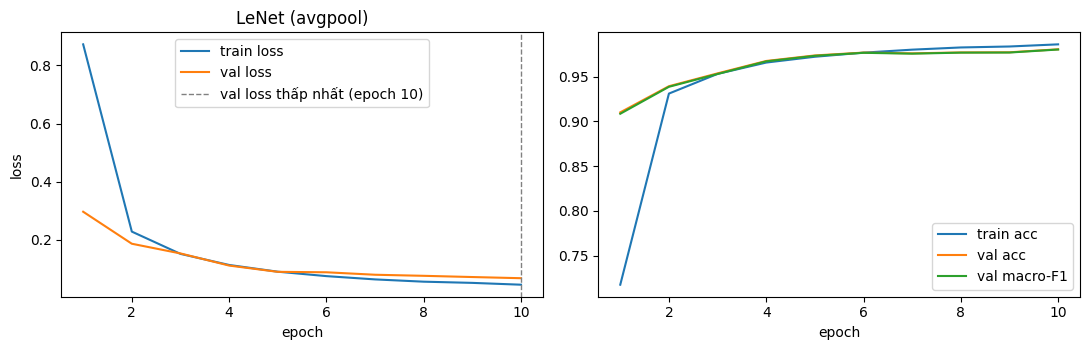


===== LeNet-5 (avgpool): kết quả trên tập TEST =====
accuracy    0.9839
precision   0.9839 (macro)
recall      0.9838 (macro)
F1          0.9838 (macro)

Precision / recall / F1 từng lớp:
              precision    recall  f1-score   support

           0     0.9858    0.9888    0.9873       980
           1     0.9947    0.9930    0.9938      1135
           2     0.9865    0.9913    0.9889      1032
           3     0.9919    0.9752    0.9835      1010
           4     0.9739    0.9878    0.9808       982
           5     0.9944    0.9865    0.9904       892
           6     0.9665    0.9927    0.9794       958
           7     0.9815    0.9825    0.9820      1028
           8     0.9895    0.9671    0.9782       974
           9     0.9742    0.9732    0.9737      1009

    accuracy                         0.9839     10000
   macro avg     0.9839    0.9838    0.9838     10000
weighted avg     0.9840    0.9839    0.9839     10000



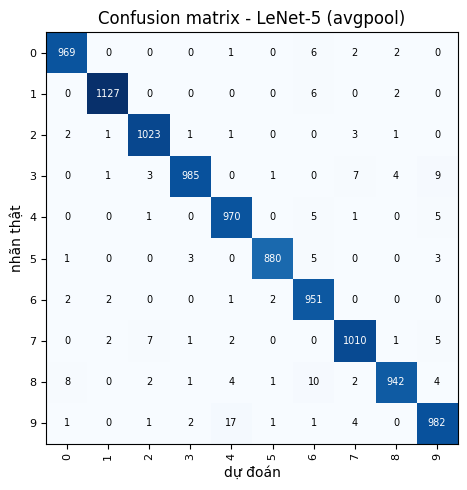

lenet_mnist_max | epoch 1/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch  1/10 | train loss 0.8197 acc 0.7304 | val loss 0.1985 acc 0.9392 F1 0.9385 | 11.1s  <- tốt nhất, đã lưu


lenet_mnist_max | epoch 2/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch  2/10 | train loss 0.1410 acc 0.9584 | val loss 0.1074 acc 0.9668 F1 0.9665 | 9.4s  <- tốt nhất, đã lưu


lenet_mnist_max | epoch 3/10:   0%|          | 0/1688 [00:00<?, ?it/s]

...

epoch  8/10 | train loss 0.0375 acc 0.9884 | val loss 0.0525 acc 0.9848 F1 0.9846 | 9.1s  <- tốt nhất, đã lưu


lenet_mnist_max | epoch 9/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch  9/10 | train loss 0.0314 acc 0.9902 | val loss 0.0490 acc 0.9858 F1 0.9856 | 9.3s  <- tốt nhất, đã lưu


lenet_mnist_max | epoch 10/10:   0%|          | 0/1688 [00:00<?, ?it/s]

epoch 10/10 | train loss 0.0286 acc 0.9910 | val loss 0.0500 acc 0.9842 F1 0.9840 | 9.5s


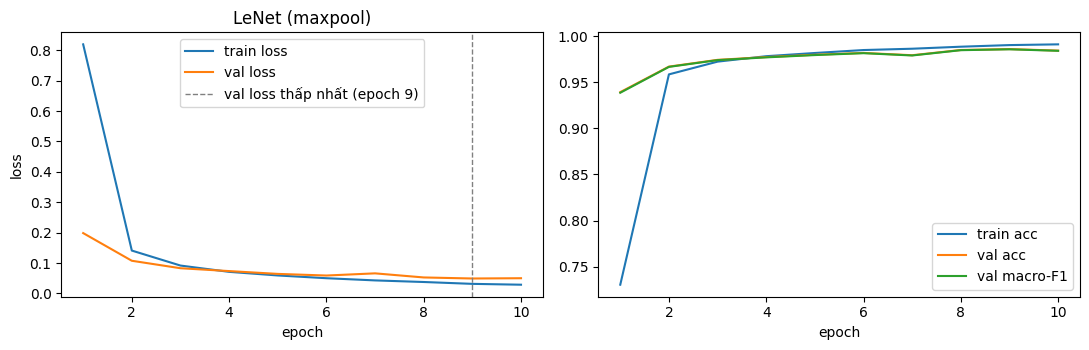


===== LeNet-5 (maxpool): kết quả trên tập TEST =====
accuracy    0.9882
precision   0.9883 (macro)
recall      0.9880 (macro)
F1          0.9881 (macro)

Precision / recall / F1 từng lớp:
              precision    recall  f1-score   support

           0     0.9918    0.9898    0.9908       980
           1     0.9904    0.9974    0.9939      1135
           2     0.9874    0.9903    0.9889      1032
           3     0.9796    0.9960    0.9877      1010
           4     0.9898    0.9929    0.9914       982
           5     0.9943    0.9776    0.9859       892
           6     0.9937    0.9864    0.9900       958
           7     0.9836    0.9903    0.9869      1028
           8     0.9846    0.9877    0.9862       974
           9     0.9879    0.9713    0.9795      1009

    accuracy                         0.9882     10000
   macro avg     0.9883    0.9880    0.9881     10000
weighted avg     0.9882    0.9882    0.9882     10000



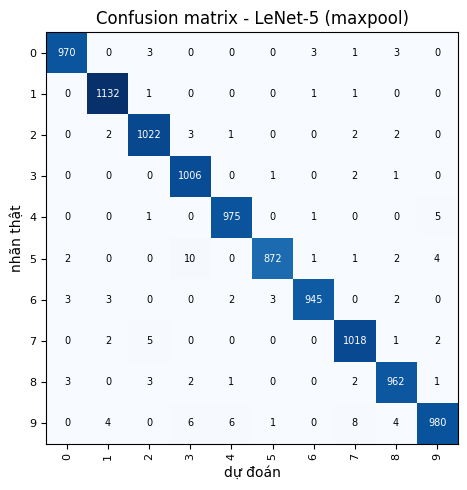

LeNet-5 (avgpool)        macro-F1 = 0.9838 | accuracy = 0.9839
LeNet-5 (maxpool)        macro-F1 = 0.9881 | accuracy = 0.9882


In [ ]:
if DATASET == "mnist":
    loaders1, RESIZE1 = build_mnist_loaders(), "28x28"
else:
    loaders1, RESIZE1 = build_vinafood_loaders(cfg["img"], augment=True), f"{cfg['img']}x{cfg['img']}"

lenet_hist = {}
for pool in ("avg", "max"):
    set_seed()
    model = LeNet(**cfg, pool=pool).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    name = f"lenet_{DATASET}_{pool}"
    lenet_hist[pool] = fit(model, loaders1, optimizer, EPOCHS["lenet"], name)
    plot_history(lenet_hist[pool], f"LeNet ({pool}pool)")
    test_model(model, loaders1, f"LeNet-5 ({pool}pool)", RESIZE1, lenet_hist[pool],
               plot_cm=True)

for r in RESULTS[-2:]:
    print(f"{r['model']:<24} macro-F1 = {r['f1']:.4f} | accuracy = {r['accuracy']:.4f}")

**Nhận xét**

- Cả hai mô hình LeNet-5 (AvgPool và MaxPool) đều đạt kết quả rất cao trên tập test. Bốn độ đo gần bằng nhau, cho thấy mô hình dự đoán đều trên các chữ số, không bị lệch về lớp nào.
- Quá trình huấn luyện ổn định: train loss và val loss cùng giảm đều, train acc và val acc sát nhau nên không có dấu hiệu overfitting. Epoch đầu có độ chính xác thấp hơn vì LeNet dùng hàm kích hoạt sigmoid nên học chậm lúc đầu, sau đó tăng nhanh.
- MaxPool hội tụ nhanh hơn và cho kết quả nhỉnh hơn AvgPool. Lý do là max pooling giữ lại đặc trưng nổi bật nhất trong mỗi vùng, phù hợp với nét chữ số, còn average pooling làm mờ bớt các đặc trưng này. Tuy nhiên chênh lệch rất nhỏ và mới chạy một lần, nên chưa thể kết luận chắc chắn.
- Chữ số 1 gần như luôn được nhận đúng vì hình dạng đơn giản, còn các chữ số có nét tròn hoặc gần giống nhau (như 8, 9, 6) dễ nhầm hơn.
- Thời gian huấn luyện của hai mô hình gần bằng nhau và rất nhanh vì mạng nhỏ, ảnh chỉ 28×28.

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer). Lưu ý lớp Convolution đầu tiên có padding là 3, các lớp Max Pooling đều bật chế độ ceil_mode (`ceil_mode=True`).


In [ ]:
from collections import OrderedDict


def conv_act(in_ch, out_ch, k, stride=1, padding=0, use_bn=True):
    layers = [nn.Conv2d(in_ch, out_ch, k, stride, padding, bias=not use_bn)]
    if use_bn:
        layers.append(nn.BatchNorm2d(out_ch))
    layers.append(nn.ReLU(inplace=True))
    return nn.Sequential(*layers)


class Inception(nn.Module):
    # 4 nhánh song song: 1x1 | 1x1 -> 3x3 | 1x1 -> 5x5 | maxpool 3x3 -> 1x1
    # channel ra = c1 + c3 + c5 + cp
    def __init__(self, in_ch, c1, c3r, c3, c5r, c5, cp, use_bn=True):
        super().__init__()
        self.b1 = conv_act(in_ch, c1, 1, use_bn=use_bn)
        self.b2 = nn.Sequential(conv_act(in_ch, c3r, 1, use_bn=use_bn),
                                conv_act(c3r, c3, 3, padding=1, use_bn=use_bn))
        self.b3 = nn.Sequential(conv_act(in_ch, c5r, 1, use_bn=use_bn),
                                conv_act(c5r, c5, 5, padding=2, use_bn=use_bn))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1),
                                conv_act(in_ch, cp, 1, use_bn=use_bn))
        self.out_ch = c1 + c3 + c5 + cp

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)


INCEPTION_CFG = [
    ("inc3a", 192,  64,  96, 128, 16,  32,  32),
    ("inc3b", 256, 128, 128, 192, 32,  96,  64),
    ("inc4a", 480, 192,  96, 208, 16,  48,  64),
    ("inc4b", 512, 160, 112, 224, 24,  64,  64),
    ("inc4c", 512, 128, 128, 256, 24,  64,  64),
    ("inc4d", 512, 112, 144, 288, 32,  64,  64),
    ("inc4e", 528, 256, 160, 320, 32, 128, 128),
    ("inc5a", 832, 256, 160, 320, 32, 128, 128),
    ("inc5b", 832, 384, 192, 384, 48, 128, 128),
]
EXPECTED_OUT = {"inc3a": 256, "inc3b": 480, "inc4a": 512, "inc4b": 512, "inc4c": 512,
                "inc4d": 528, "inc4e": 832, "inc5a": 832, "inc5b": 1024}


def maxpool():
    return nn.MaxPool2d(3, stride=2, ceil_mode=True)


class GoogLeNet(nn.Module):
    def __init__(self, num_classes=21, in_ch=3, use_bn=True, dropout=0.4):
        super().__init__()
        cfg = {c[0]: c for c in INCEPTION_CFG}
        inc = lambda n: (n, Inception(*cfg[n][1:], use_bn=use_bn))
        self.features = nn.Sequential(OrderedDict([
            ("conv1",  conv_act(in_ch, 64, 7, stride=2, padding=3, use_bn=use_bn)),
            ("pool1",  maxpool()),
            ("conv2a", conv_act(64, 64, 1, use_bn=use_bn)),
            ("conv2b", conv_act(64, 192, 3, padding=1, use_bn=use_bn)),
            ("pool2",  maxpool()),
            inc("inc3a"), inc("inc3b"), ("pool3", maxpool()),
            inc("inc4a"), inc("inc4b"), inc("inc4c"), inc("inc4d"), inc("inc4e"), ("pool4", maxpool()),
            inc("inc5a"), inc("inc5b"),
        ]))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(dropout), nn.Linear(1024, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


assert n_params(Inception(1, 16, 16, 24, 4, 8, 8, use_bn=False)) == 4376
set_seed()
g = GoogLeNet(num_classes=21)
print(f"GoogLeNet: {n_params(g):,} tham số (21 lớp)")
x = torch.zeros(1, 3, IMG["googlenet"], IMG["googlenet"])
g.eval()
with torch.no_grad():
    print(f"\n{'layer':<8}{'output shape':<22}")
    for name, layer in g.features.named_children():
        x = layer(x)
        print(f"{name:<8}{str(tuple(x.shape)):<22}")
        if name in EXPECTED_OUT:
            assert x.shape[1] == EXPECTED_OUT[name], name
    print("head ->", tuple(g.head(x).shape))
print("\nSố channel ra của các Inception block đều khớp bảng của đề.")

GoogLeNet: 6,002,357 tham số (21 lớp)

layer   output shape          
conv1   (1, 64, 112, 112)     
pool1   (1, 64, 56, 56)       
conv2a  (1, 64, 56, 56)       
conv2b  (1, 192, 56, 56)      
pool2   (1, 192, 28, 28)      
inc3a   (1, 256, 28, 28)      
inc3b   (1, 480, 28, 28)      
pool3   (1, 480, 14, 14)      
inc4a   (1, 512, 14, 14)      
inc4b   (1, 512, 14, 14)      
inc4c   (1, 512, 14, 14)      
inc4d   (1, 528, 14, 14)      
inc4e   (1, 832, 14, 14)      
pool4   (1, 832, 7, 7)        
inc5a   (1, 832, 7, 7)        
inc5b   (1, 1024, 7, 7)       
head -> (1, 21)

Số channel ra của các Inception block đều khớp bảng của đề.


VinaFood21 @ /content/VinaFood21 | 21 lớp | train 9040 / val 1004 / test 6682 | ảnh 224x224 | augment=True


googlenet | epoch 1/50:   0%|          | 0/283 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1/50 | train loss 2.7295 acc 0.1782 | val loss 2.6639 acc 0.1992 F1 0.1185 | 180.6s  <- tốt nhất, đã lưu


googlenet | epoch 2/50:   0%|          | 0/283 [00:00<?, ?it/s]

...

epoch 48/50 | train loss 0.3574 acc 0.8796 | val loss 1.0255 acc 0.7131 F1 0.7149 | 157.3s


googlenet | epoch 49/50:   0%|          | 0/283 [00:00<?, ?it/s]

epoch 49/50 | train loss 0.3556 acc 0.8812 | val loss 0.9990 acc 0.7420 F1 0.7401 | 155.9s  <- tốt nhất, đã lưu


googlenet | epoch 50/50:   0%|          | 0/283 [00:00<?, ?it/s]

epoch 50/50 | train loss 0.3370 acc 0.8887 | val loss 1.1071 acc 0.7131 F1 0.7176 | 154.6s


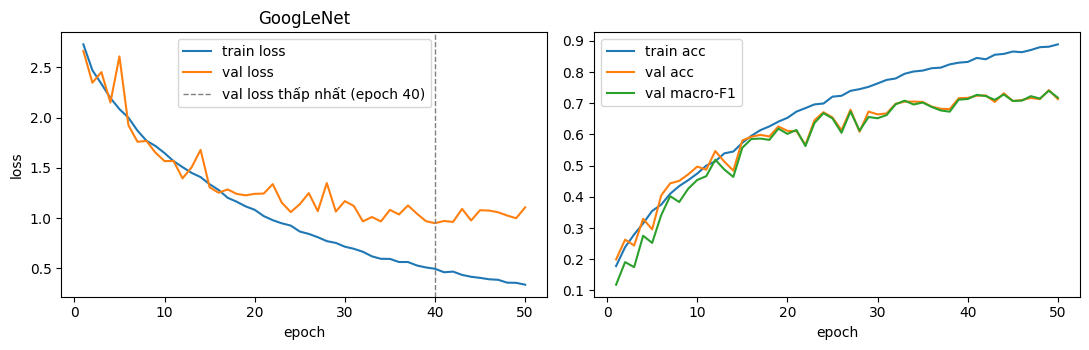


===== GoogLeNet: kết quả trên tập TEST =====
accuracy    0.6625
precision   0.6713 (macro)
recall      0.6571 (macro)
F1          0.6520 (macro)

Precision / recall / F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.7046    0.6929    0.6987       241
        banh-hoi     0.7469    0.7002    0.7228       607
    banh-mi-chao     0.6418    0.8616    0.7356       289
        banh-tet     0.8320    0.5714    0.6775       364
 banh-trang-tron     0.5467    0.7767    0.6417       309
          banh-u     0.4650    0.8295    0.5959       176
        banh-uot     0.6430    0.5018    0.5637       560
       bap-nuong     0.6415    0.4755    0.5462       143
          bo-kho     0.6466    0.6982    0.6714       338
       bo-la-lot     0.8886    0.6790    0.7698       458
       bot-chien     0.6522    0.5978    0.6238       276
           ca-ri     0.5000    0.3099    0.3827       171
    canh-kho-qua     0.6702    0.8828    0.7619       290
   can

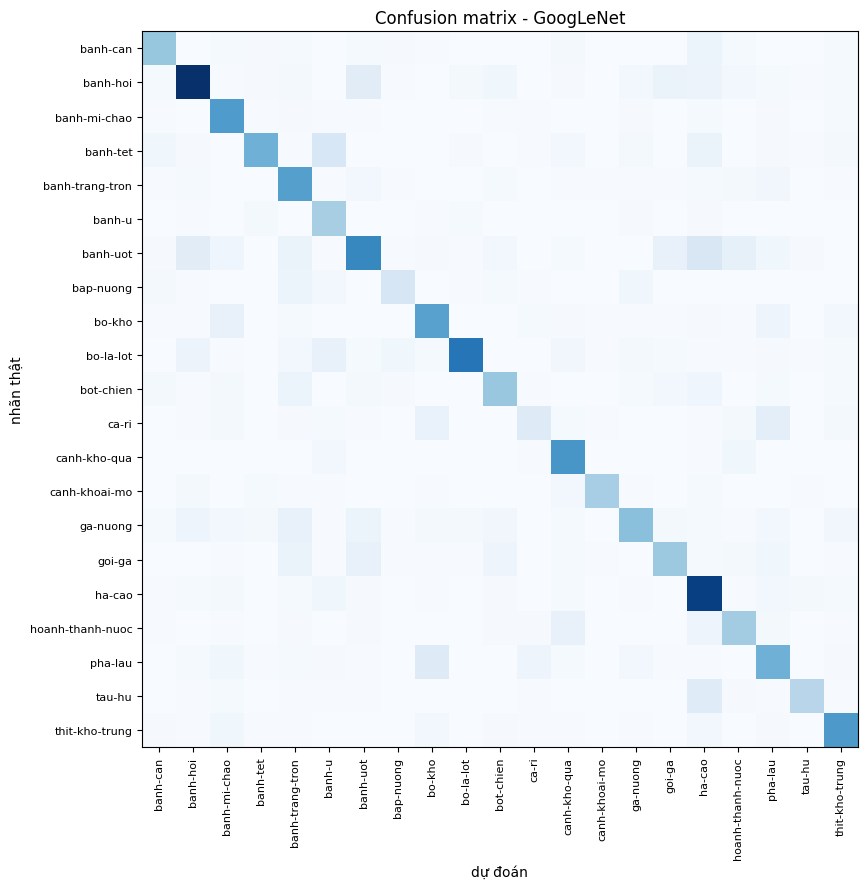

{'accuracy': 0.6625261897635438,
 'precision': 0.6712958088978181,
 'recall': 0.6570534662694839,
 'f1': 0.6519880534630026}

In [ ]:
loaders2 = build_vinafood_loaders(IMG["googlenet"], augment=True)
RESIZE2 = f"{IMG['googlenet']}x{IMG['googlenet']}"

set_seed()
model = GoogLeNet(num_classes=len(loaders2["classes"])).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
googlenet_hist = fit(model, loaders2, optimizer, EPOCHS["googlenet"], "googlenet")
plot_history(googlenet_hist, "GoogLeNet")
test_model(model, loaders2, "GoogLeNet", RESIZE2, googlenet_hist)

**Nhận xét**

- Kết quả trên tập test thấp hơn nhiều so với MNIST. Lý do là ảnh món ăn thật rất đa dạng về góc chụp và ánh sáng, nhiều món trông khá giống nhau, và dữ liệu khá ít để huấn luyện một mạng sâu từ đầu.
- Train loss giảm đều nhưng val loss chỉ giảm đến một mức rồi dao động, đồng thời train acc cao hơn val acc rõ rệt. Điều này cho thấy mô hình bắt đầu overfitting ở giai đoạn sau.
- Val acc dao động mạnh giữa các epoch vì tập val nhỏ và có dùng augmentation. Kết quả test thấp hơn val vì checkpoint được chọn theo val tốt nhất, và tập test có thể khác phân phối với tập train.
- Một số món nhận diện tốt (như canh khoai mỡ, bò lá lốt) nhờ hình dạng và màu sắc đặc trưng. Một số món nhận diện kém (như cà ri, gà nướng, bắp nướng) vì dễ nhầm với món khác có màu sắc và hình dạng gần giống.
- GoogLeNet tốn thời gian huấn luyện hơn LeNet rất nhiều do ảnh lớn hơn và mô hình có nhiều tham số hơn.
- Có thể cải thiện bằng transfer learning, thêm learning rate scheduler, hoặc dùng thêm dữ liệu.

### Bảng tổng hợp kết quả

Số liệu lấy từ các lần chạy Bài 1 và Bài 2, tính trên tập **test**.

In [ ]:
show_results()

Mô hình                              Resize      Tham số  Giây/epoch     Acc    Prec  Recall  macro-F1
LeNet-5 (avgpool)                     28x28       61,706        10.0  0.9839  0.9839  0.9838    0.9838
LeNet-5 (maxpool)                     28x28       61,706         9.6  0.9882  0.9883  0.9880    0.9881
GoogLeNet                           224x224    6,002,357       156.8  0.6625  0.6713  0.6571    0.6520
